# Fine-tuning

In [2]:
import os
os.chdir("/content")
!pip -q install psutil

In [3]:
import pandas as pd
from IPython.display import Image, display

import pretrained_classification as pc

In [4]:
args = pc.parse_args([])
args.train_size = 10000
args.val_size = 1000
args.test_size = 5000
args.ood_size = 5000
args.epochs = 3
args.max_len = 128
df = pc.run_all(args)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

... (40 outputs left out)

pretrained trainable 1.0 64 0.8148


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


pretrained trainable 1.0 256 0.899


In [5]:
df[df.eval_set == "imdb_test"]

,model_name,model_type,encoder_trainable,train_frac,max_len,eval_set,accuracy,precision,recall,f1,train_time_s,total_params,trainable_params,peak_mem_mb,seed,hardware
0,distilbert-base-uncased,pretrained,True,1.00,128,imdb_test,0.8746,0.886149,0.860335,0.873051,334.437060,66364418,66364418,2291.061523,42,Tesla T4
2,scratch_transformer,scratch,True,1.00,128,imdb_test,0.8032,0.824659,0.771349,0.797113,21.026894,9525762,9525762,311.650391,42,Tesla T4
4,distilbert-base-uncased,pretrained,False,1.00,128,imdb_test,0.7890,0.794082,0.781724,0.787854,109.804026,66364418,1538,411.702637,42,Tesla T4
6,distilbert-base-uncased,pretrained,True,0.10,128,imdb_test,0.8290,0.799203,0.879888,0.837607,34.390071,66364418,66364418,2305.061523,42,Tesla T4
8,scratch_transformer,scratch,True,0.10,128,imdb_test,0.6610,0.651702,0.695132,0.672717,2.108094,9525762,9525762,311.650391,42,Tesla T4
10,distilbert-base-uncased,pretrained,True,0.25,128,imdb_test,0.8514,0.845551,0.860734,0.853075,85.569997,66364418,66364418,2303.436523,42,Tesla T4
12,scratch_transformer,scratch,True,0.25,128,imdb_test,0.7760,0.747500,0.835196,0.788918,5.161728,9525762,9525762,311.650391,42,Tesla T4
14,distilbert-base-uncased,pretrained,True,0.50,128,imdb_test,0.8624,0.850694,0.879888,0.865045,172.327125,66364418,66364418,2305.061523,42,Tesla T4
16,scratch_transformer,scratch,True,0.50,128,imdb_test,0.7814,0.763718,0.816441,0.789200,10.314519,9525762,9525762,311.650391,42,Tesla T4
18,distilbert-base-uncased,pretrained,True,1.00,64,imdb_test,0.8148,0.810291,0.823224,0.816706,181.437251,66364418,66364418,1688.389648,42,Tesla T4


In [6]:
full = df[(df.train_frac == 1.0) & (df.max_len == args.max_len)]
pd.pivot_table(full, index=["model_type", "encoder_trainable"], columns="eval_set", values=["accuracy", "f1"])

accuracy                   f1          
eval_set                     amazon_ood imdb_test amazon_ood imdb_test
model_type encoder_trainable                                          
pretrained False                 0.8214    0.7890   0.833984  0.787854
           True                  0.8950    0.8746   0.899290  0.873051
scratch    True                  0.7472    0.8032   0.760334  0.797113

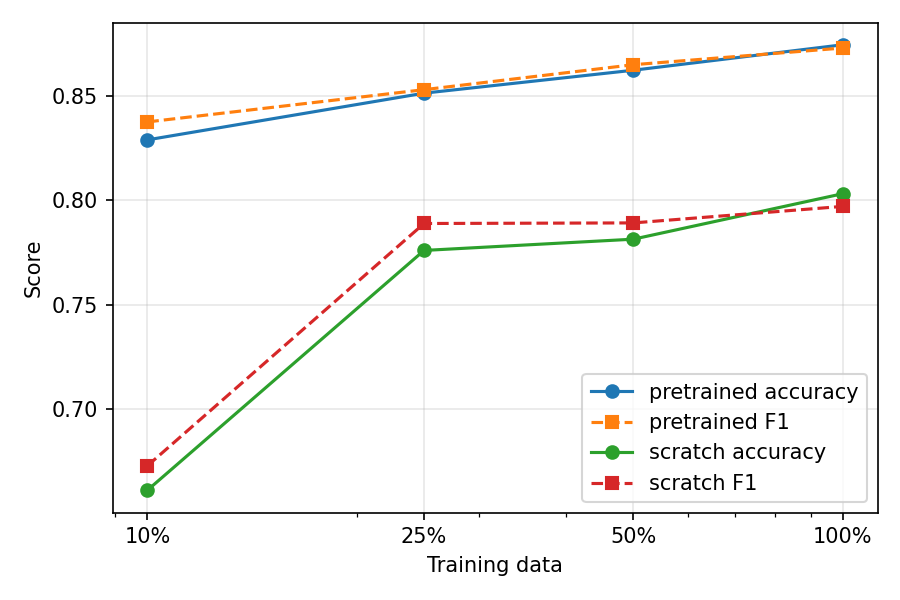

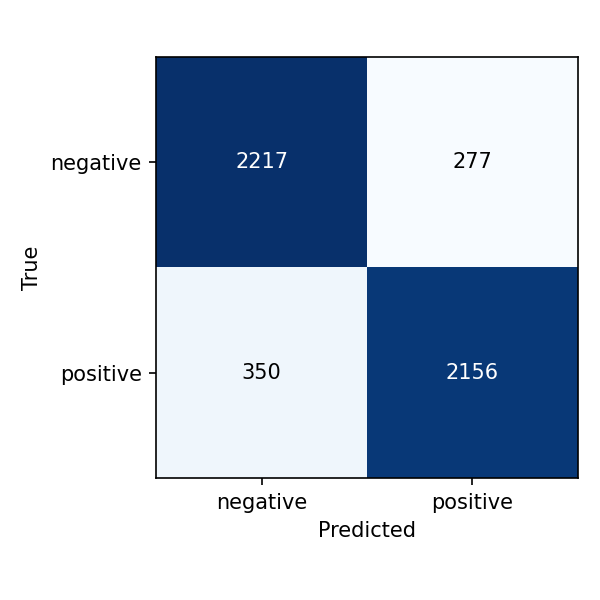

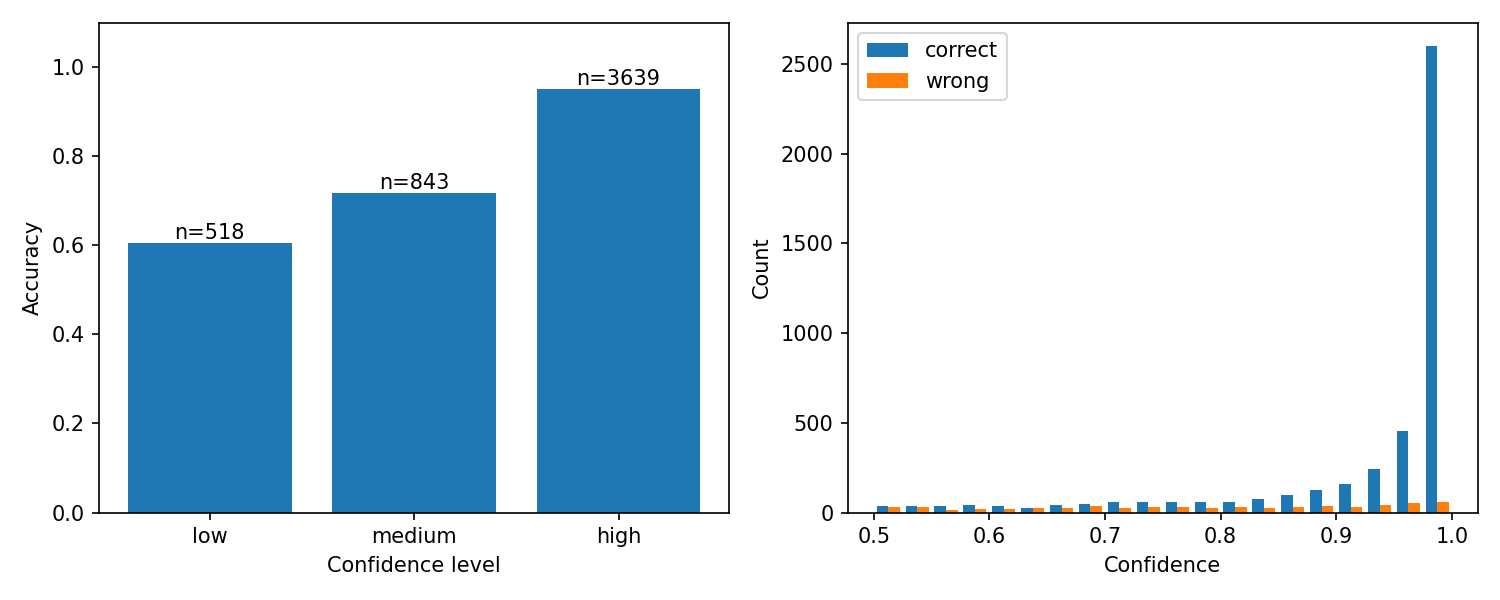

In [7]:
for path in ["data_efficiency.png", "confusion_matrix.png", "confidence_analysis.png"]:
    display(Image(path))

In [8]:
!zip -q lab08_outputs.zip results.csv data_efficiency.png confusion_matrix.png confidence_analysis.png error_analysis.md error_samples.csv
from google.colab import files
files.download("lab08_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>